<h1 style="color: darkgray;font-family:san=serif;text-align:right;font-weight:bold;font-size:30px">Import Libraries</h1>

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import random
from sklearn.model_selection import train_test_split
# from lib_file import lib_path
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

import os
for dirname,_,filenames in os.walk('input'):
    for filename in filenames:
        print(os.path.join(dirname,filename))

input\WebPhishing_data.csv


<h1 style="color: darkgray;font-family:san=serif;text-align:right;font-weight:bold;font-size:30px">Data Loading</h1>

In [2]:
df = pd.read_csv('input/WebPhishing_data.csv')

***Preliminary Analysis***

In [3]:
df.head()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url,label
0,80,15,16,2,2,0,0,1,0,3,3,1,1,1,0,64,2,1,1,benign
1,68,23,37,21,2,0,0,0,0,5,0,1,1,1,0,58,2,1,1,benign
2,52,25,19,18,3,0,0,0,0,2,0,1,1,1,0,45,1,1,1,benign
3,124,22,94,2,3,11,0,0,0,3,0,1,1,1,7,95,5,1,1,benign
4,28,19,1,0,3,0,0,0,0,2,0,1,1,1,1,21,1,1,1,benign


In [4]:
df.shape

(691476, 20)

<h1 style="color: darkgray;font-family:san=serif;text-align:right;font-weight:bold;font-size:30px">Data Preprocessing</h1>

In [7]:
df.isnull().sum()

url_length         0
hostname_length    0
path_length        0
fd_length          0
tld_length         0
count-             0
count@             0
count?             0
count%             0
count.             0
count=             0
count-http         0
count-https        0
count-www          0
count-digits       0
count-letters      0
count_dir          0
use_of_ip          0
short_url          0
label              0
dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 691476 entries, 0 to 691475
Data columns (total 20 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   url_length       691476 non-null  int64 
 1   hostname_length  691476 non-null  int64 
 2   path_length      691476 non-null  int64 
 3   fd_length        691476 non-null  int64 
 4   tld_length       691476 non-null  int64 
 5   count-           691476 non-null  int64 
 6   count@           691476 non-null  int64 
 7   count?           691476 non-null  int64 
 8   count%           691476 non-null  int64 
 9   count.           691476 non-null  int64 
 10  count=           691476 non-null  int64 
 11  count-http       691476 non-null  int64 
 12  count-https      691476 non-null  int64 
 13  count-www        691476 non-null  int64 
 14  count-digits     691476 non-null  int64 
 15  count-letters    691476 non-null  int64 
 16  count_dir        691476 non-null  int64 
 17  use_of_ip 

***Visualizations***

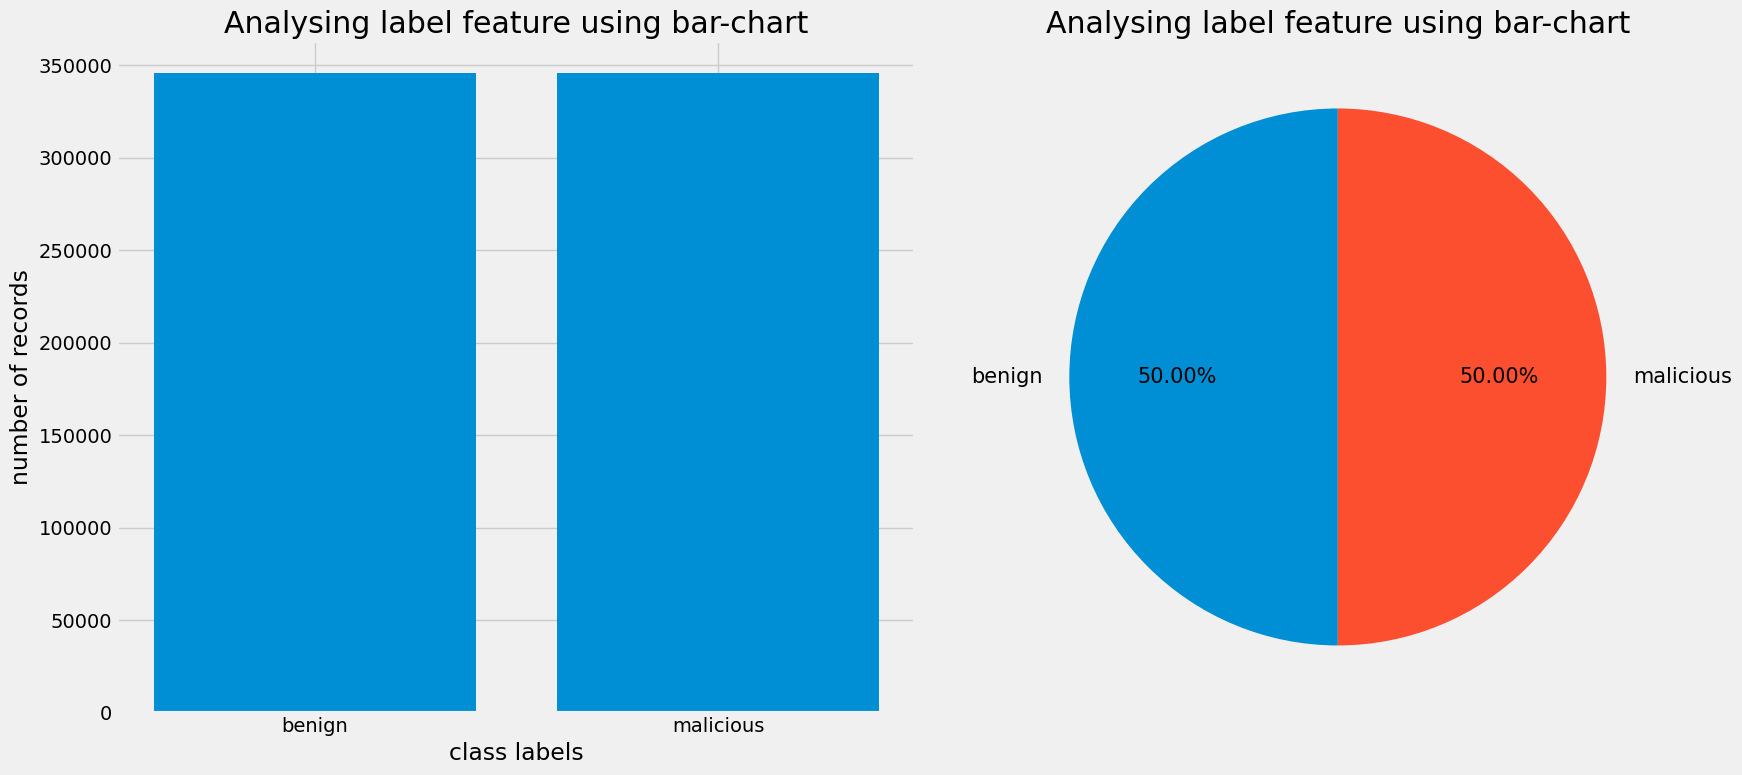

In [9]:
with plt.style.context(style='fivethirtyeight'):
    vis_data=dict(df['label'].value_counts())
    fig,axes=plt.subplots(nrows=1,ncols=2,figsize=(18,8))
    plt.rcParams['font.size']=15
    axes[0].bar(x=list(vis_data.keys()),
                height=list(vis_data.values()))
    axes[0].set_title(label='Analysing label feature using bar-chart')
    axes[0].set_xlabel(xlabel='class labels')
    axes[0].set_ylabel(ylabel='number of records')
    axes[1].pie(labels=list(vis_data.keys()),
                x=list(vis_data.values()),
                autopct='%.2f%%',
                pctdistance=0.60,
                startangle=90)
    axes[1].set_title(label='Analysing label feature using bar-chart')
    fig.tight_layout()
    plt.show()

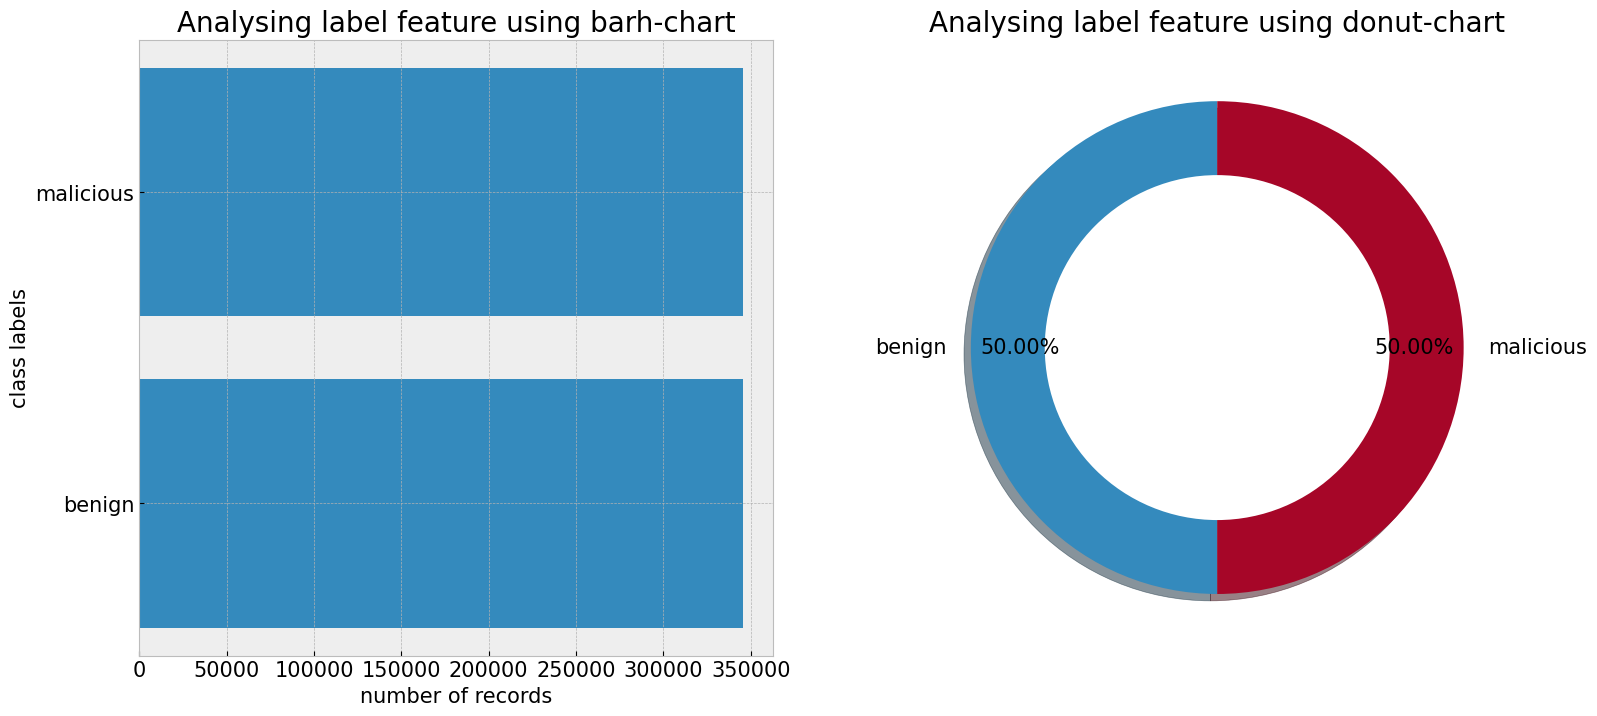

In [10]:
with plt.style.context(style='bmh'):
    viz_data = dict(df['label'].value_counts())
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 8))
    
    axes[0].barh(y=list(viz_data.keys()), width=list(viz_data.values()))
    axes[0].set_title(label='Analysing label feature using barh-chart', fontsize=20)
    axes[0].set_xlabel(xlabel='number of records', fontsize=15)
    axes[0].set_ylabel(ylabel='class labels', fontsize=15)
    axes[0].tick_params(axis='both', labelsize=15)

    axes[1].pie(x=list(viz_data.values()), labels=list(viz_data.keys()),
                autopct='%.2f%%', pctdistance=0.80,
                startangle=90, shadow=True, textprops={'fontsize': 15})
    center_circle = plt.Circle((0, 0), 0.7, fc='white')
    figure = plt.gcf()
    figure.gca().add_artist(center_circle)
    axes[1].set_title(label='Analysing label feature using donut-chart', fontsize=20)
    plt.show()

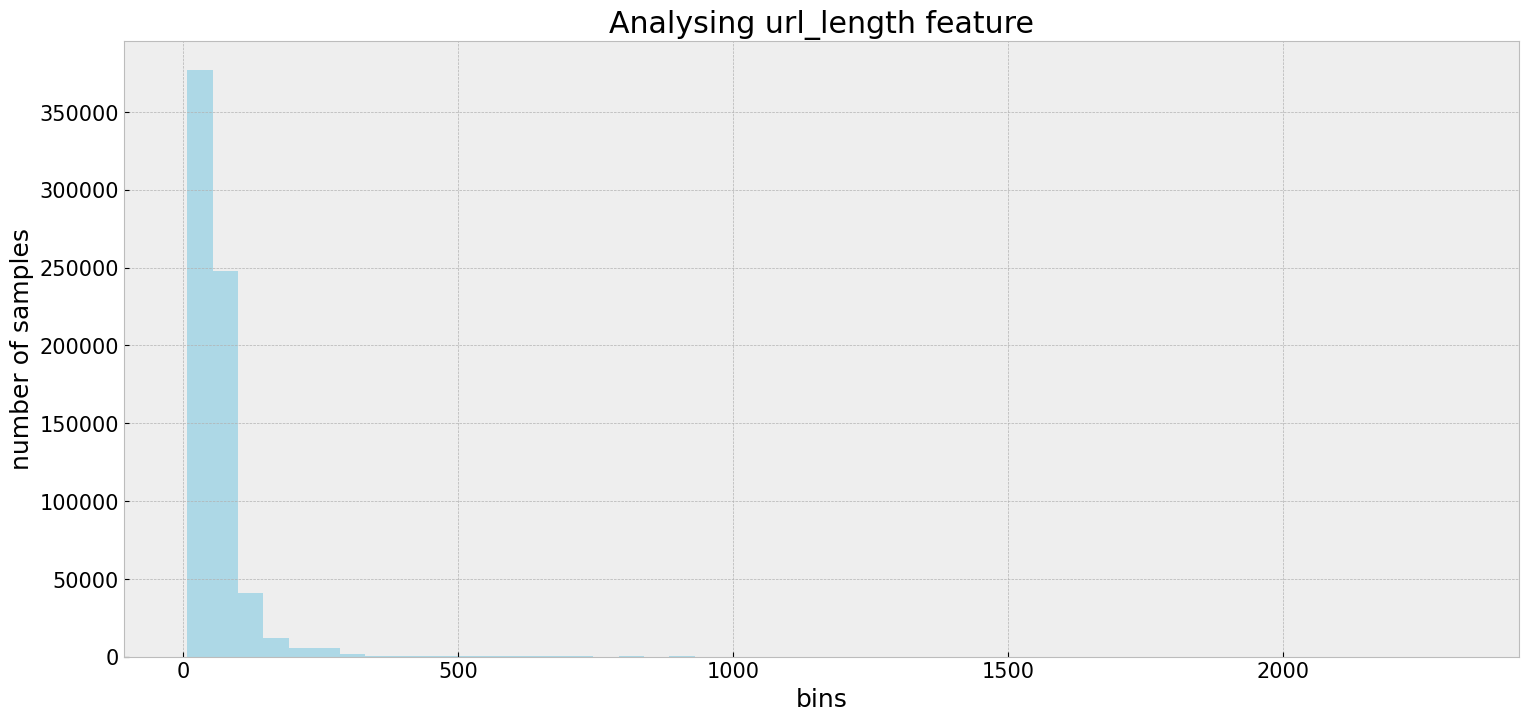

In [11]:
with plt.style.context(style='bmh'):
    plt.figure(figsize=(18,8))
    plt.rcParams['font.size']=15
    plt.hist(df['url_length'],bins=50,color='LightBlue')
    plt.title(label='Analysing url_length feature')
    plt.xlabel(xlabel="bins")
    plt.ylabel(ylabel="number of samples")
    plt.show()

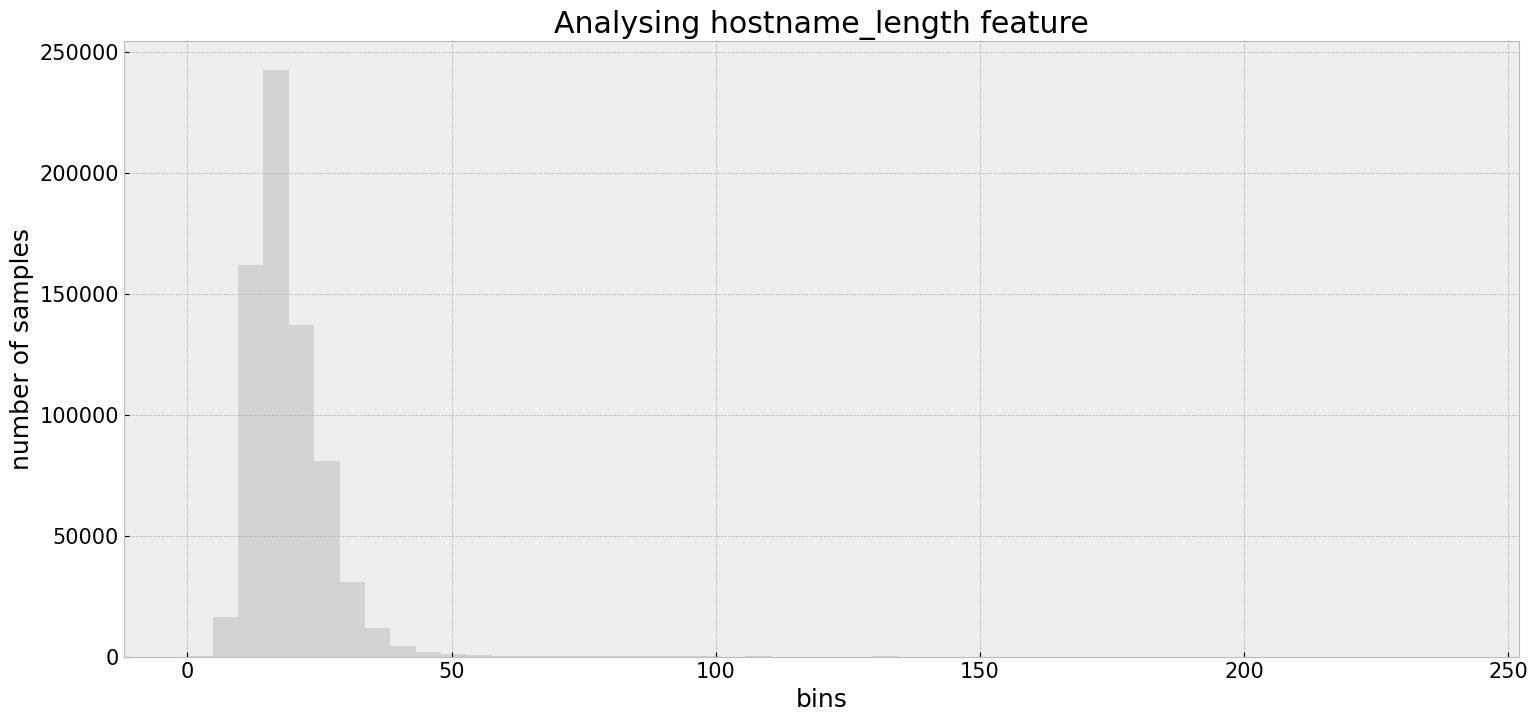

In [12]:
with plt.style.context(style='bmh'):
    plt.figure(figsize=(18,8))
    plt.rcParams['font.size']=15
    plt.hist(df['hostname_length'],bins=50,color='lightgray')
    plt.title(label='Analysing hostname_length feature')
    plt.xlabel(xlabel="bins")
    plt.ylabel(ylabel="number of samples")
    plt.show()

***Label Encoding***

In [13]:
df.head()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url,label
0,80,15,16,2,2,0,0,1,0,3,3,1,1,1,0,64,2,1,1,benign
1,68,23,37,21,2,0,0,0,0,5,0,1,1,1,0,58,2,1,1,benign
2,52,25,19,18,3,0,0,0,0,2,0,1,1,1,0,45,1,1,1,benign
3,124,22,94,2,3,11,0,0,0,3,0,1,1,1,7,95,5,1,1,benign
4,28,19,1,0,3,0,0,0,0,2,0,1,1,1,1,21,1,1,1,benign


In [14]:
df.tail()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url,label
691471,108,17,34,7,3,2,0,2,0,5,1,1,0,2,3,84,5,1,1,malicious
691472,111,9,65,5,3,0,1,1,2,7,1,1,0,1,2,89,5,1,-1,malicious
691473,105,11,64,10,5,0,0,1,0,2,0,1,0,0,19,69,10,1,1,malicious
691474,73,21,45,4,3,0,0,0,0,5,0,1,0,1,10,51,4,1,1,malicious
691475,35,11,17,3,3,0,0,0,0,1,0,1,0,0,0,27,4,1,1,malicious


In [15]:
class_labels=df['label'].unique().tolist()
class_labels.sort()
print(class_labels)

['benign', 'malicious']


In [16]:
class_dict={}
for idx,label in enumerate(class_labels):
    class_dict[label]=idx
print(class_dict)

{'benign': 0, 'malicious': 1}


In [17]:
df['label'] = df['label'].map(class_dict)
df.head()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url,label
0,80,15,16,2,2,0,0,1,0,3,3,1,1,1,0,64,2,1,1,0
1,68,23,37,21,2,0,0,0,0,5,0,1,1,1,0,58,2,1,1,0
2,52,25,19,18,3,0,0,0,0,2,0,1,1,1,0,45,1,1,1,0
3,124,22,94,2,3,11,0,0,0,3,0,1,1,1,7,95,5,1,1,0
4,28,19,1,0,3,0,0,0,0,2,0,1,1,1,1,21,1,1,1,0


In [18]:
df.tail()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url,label
691471,108,17,34,7,3,2,0,2,0,5,1,1,0,2,3,84,5,1,1,1
691472,111,9,65,5,3,0,1,1,2,7,1,1,0,1,2,89,5,1,-1,1
691473,105,11,64,10,5,0,0,1,0,2,0,1,0,0,19,69,10,1,1,1
691474,73,21,45,4,3,0,0,0,0,5,0,1,0,1,10,51,4,1,1,1
691475,35,11,17,3,3,0,0,0,0,1,0,1,0,0,0,27,4,1,1,1


***Data shuffling***

In [19]:
df = df.sample(frac=1).reset_index(drop=True)
df.head(20)

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url,label
0,66,17,42,9,6,0,0,0,0,3,0,1,0,0,0,55,5,1,1,1
1,26,17,1,0,3,0,0,0,0,3,0,1,1,1,0,19,1,1,1,0
2,78,17,12,1,3,4,0,1,0,3,1,1,1,1,23,39,2,1,1,0
3,63,19,36,6,3,2,0,0,0,2,0,1,1,1,0,52,4,1,1,0
4,75,24,44,14,4,0,0,0,1,1,0,1,0,0,2,65,3,1,1,1
5,67,20,40,38,3,0,0,0,0,1,0,1,0,0,0,61,2,1,1,1
6,57,20,29,5,3,0,0,0,0,3,0,1,1,1,10,38,3,1,1,0
7,51,28,8,7,3,0,0,1,0,3,1,1,1,1,2,40,1,1,1,0
8,52,15,22,7,3,0,0,1,0,3,1,1,0,1,0,41,3,1,1,1
9,73,12,54,9,5,0,0,0,0,3,0,1,0,0,0,62,5,1,1,1


***Data Splitting***

In [20]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1:]

In [21]:
X.head()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url
0,66,17,42,9,6,0,0,0,0,3,0,1,0,0,0,55,5,1,1
1,26,17,1,0,3,0,0,0,0,3,0,1,1,1,0,19,1,1,1
2,78,17,12,1,3,4,0,1,0,3,1,1,1,1,23,39,2,1,1
3,63,19,36,6,3,2,0,0,0,2,0,1,1,1,0,52,4,1,1
4,75,24,44,14,4,0,0,0,1,1,0,1,0,0,2,65,3,1,1


In [22]:
y.head()

,label
0,1
1,0
2,0
3,0
4,1


<h1 style="color: darkgray;font-family:san=serif;text-align:right;font-weight:bold;font-size:30px">Data Splitting</h1>

In [23]:
X_train,X_test,y_train,y_test=train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(553180, 19) (138296, 19) (553180, 1) (138296, 1)


In [24]:
X_train.head()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url
406613,76,13,56,8,2,1,0,0,0,2,0,1,0,1,21,44,5,1,1
178080,43,15,6,5,3,0,0,1,0,2,1,1,1,1,2,33,1,1,1
379125,70,14,48,33,3,4,0,0,0,2,0,1,1,1,10,48,3,1,1
602623,36,12,16,4,3,0,0,0,0,2,0,1,1,1,7,21,3,1,1
621100,36,12,16,4,3,0,0,0,0,2,0,1,1,1,7,21,3,1,1


In [25]:
y_train.head()

,label
406613,1
178080,0
379125,0
602623,0
621100,0


In [26]:
X_test.head()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url
181805,65,12,7,6,3,1,0,1,0,3,1,1,0,0,1,49,1,1,1
326743,31,12,12,11,3,0,0,0,0,1,0,1,0,0,2,24,1,1,1
677944,45,24,13,11,3,2,0,0,0,2,0,1,1,1,0,36,2,1,-1
38962,105,15,82,6,3,10,0,0,0,2,0,1,1,1,8,78,4,1,1
350478,48,12,28,7,3,1,0,0,0,3,0,1,1,1,0,38,3,1,1


In [27]:
y_test.head()

,label
181805,1
326743,1
677944,0
38962,0
350478,0


In [28]:
X_train.to_csv("SplittedData/X_train.csv", index=False)
X_test.to_csv("SplittedData/X_test.csv", index=False)
y_train.to_csv("SplittedData/y_train.csv", index=False)
y_test.to_csv("SplittedData/y_test.csv", index=False)

---